**Navigation** : [Version Python](ML-09b-TSAD-Benchmark-Flaws-Python.ipynb) | [ML-09](ML-09-Anomaly-Detection-Python.ipynb) | [ML-09c C#](ML-09c-MatrixProfile-Multidim-CSharp.ipynb) | [Index](README.md)

# ML-09b — Évaluer des détecteurs sur cinq séries UCR en C#

**Objectifs** : comparer SPC et MLP, distinguer classement et seuil, examiner densité, annotations et position. **Prérequis** : statistiques, ROC/AUC, C# et CPython. **Durée** : 90 minutes.

Le [Python versionné](ML-09b-TSAD-Benchmark-Flaws-Python.ipynb) est la source pédagogique primaire et conserve le contexte bibliographique historique. Les expériences ci-dessous ne reproduisent pas les évaluations externes et ne prouvent pas qu'une archive entière est « honnête » ou « triviale ».

C# charge/parse les séries, construit les fenêtres et cibles, calcule scores SPC/AUC/densités/décalages et trace les figures. Python.NET appelle le vrai MLPRegressor et StandardScaler scikit-learn ; le chargeur UCR versionné vérifie les octets et récupère les membres ZIP par HTTP Range. Une régression/ACP de substitution n'exercerait pas le même modèle non linéaire. Installer NumPy et scikit-learn dans un CPython pris en charge, puis lancer un noyau C# neuf. Le chargeur commun découvre ce CPython ; `PYTHONNET_PYDLL` permet un choix explicite cohérent avec son environnement.

In [1]:
// Le GIL protège chaque échange avec CPython, y compris la libération des objets.
// C# prépare les fenêtres et les métriques ; ce pont appelle les vrais estimateurs sklearn.
#r "nuget: PythonNet, 3.1.0"
#load "../../Config/PythonNetLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using System.IO;
using System.Text;
using System.Text.Json;
using System.Text.RegularExpressions;
using System.Globalization;
using System.Security.Cryptography;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "sklearn");
    PythonEngine.BeginAllowThreads();
}

string Backend(string code, object config)
{
    using (Py.GIL())
    {
        using var scope = Py.CreateScope();
        using var input = new PyString(JsonSerializer.Serialize(config));
        scope.Set("config_json", input);
        scope.Exec("import json\ncfg=json.loads(config_json)\n" + code);
        using var result = scope.Get("result_json");
        return result.As<string>();
    }
}

Console.WriteLine($".NET {Environment.Version} ; Python.NET {typeof(PythonEngine).Assembly.GetName().Version}");
Console.WriteLine(Backend("import sys,numpy,sklearn\nresult_json=json.dumps({'python':sys.version.split()[0],'numpy':numpy.__version__,'sklearn':sklearn.__version__})", new { }));


Installed Packages PythonNet, 3.1.0

.NET 10.0.14 ; Python.NET 3.1.0.0


{"python": "3.13.16", "numpy": "2.4.4", "sklearn": "1.8.0"}


## 1. Score SPC et données vérifiées

Les cinq fichiers sont lus depuis l'archive UCR officielle via le chargeur existant `ucr_anomaly_fetch.py`. Taille et SHA-256 sont épinglés dans `ucr_anomaly_manifest.json` ; le cache `data/tsad` est ignoré par Git. Un échec réseau/intégrité est visible, sans série synthétique de remplacement ni redistribution.

Le score est |x−moyenne|/écart-type (population). Moyenne et dispersion utilisent toute la série : diagnostic transductif/descriptif, pas pipeline prospectif sans futur. La décision stricte >3 est distincte de l'AUC, calculée par comparaison des rangs positifs/négatifs, avec demi-crédit aux ex æquo.

Les derniers champs du nom définissent [début,fin] inclusifs. Le champ précédent est l'indication de train de l'archive ; l'expérience conserve le protocole propre de première moitié pour le MLP, distinct de ce découpage officiel.

In [2]:
// Les octets UCR sont vérifiés par le chargeur avant tout calcul, puis parsés en C#.
// Les bornes inclusives du nom de fichier définissent les labels ; le score SPC reste global et descriptif.
record SerieUcr(string Nom, double[] Valeurs, int[] Labels, int Debut, int Fin, string Sha256);
string DossierUcr()
{
    for (var d = new DirectoryInfo(Directory.GetCurrentDirectory()); d != null; d = d.Parent)
    {
        foreach (var q in new[]
        {
            d.FullName,
            Path.Combine(d.FullName, "MyIA.AI.Notebooks", "ML", "ML.Net")
        }

        )
            if (File.Exists(Path.Combine(q, "ucr_anomaly_fetch.py")))
                return q;
    }

    throw new FileNotFoundException("ucr_anomaly_fetch.py absent : ouvrir depuis le dépôt CoursIA.");
}

string dossierUcr = DossierUcr();
SerieUcr Charger(string fichier)
{
    string result = Backend("import sys,hashlib,os\nsys.path.insert(0,cfg['folder'])\nfrom ucr_anomaly_fetch import fetch_raw\nb=fetch_raw(cfg['name'],cache_dir=os.path.join(cfg['folder'],'data','tsad'))\nresult_json=json.dumps({'text':b.decode('utf-8','replace'),'sha256':hashlib.sha256(b).hexdigest()})", new { folder = dossierUcr, name = fichier });
    using var d = JsonDocument.Parse(result);
    string texte = d.RootElement.GetProperty("text").GetString();
    string hash = d.RootElement.GetProperty("sha256").GetString();
    var valeurs = Regex.Split(texte.Replace(',', ' '), @"\s+").Where(t => double.TryParse(t, NumberStyles.Float, CultureInfo.InvariantCulture, out _)).Select(t => double.Parse(t, CultureInfo.InvariantCulture)).ToArray();
    var m = Regex.Match(fichier, @"^\d+_UCR_Anomaly_(.+)_\d+_(\d+)_(\d+)\.txt$");
    if (!m.Success)
        throw new ArgumentException("Nom UCR invalide.");
    int start = Math.Max(0, int.Parse(m.Groups[2].Value)), end = Math.Min(valeurs.Length - 1, int.Parse(m.Groups[3].Value));
    var labels = new int[valeurs.Length];
    for (int i = start; i <= end; i++)
        labels[i] = 1;
    if (valeurs.Length == 0 || valeurs.Any(v => !double.IsFinite(v)))
        throw new Exception("Série vide ou non finie.");
    return new SerieUcr(m.Groups[1].Value, valeurs, labels, start, end, hash);
}

double Moy(double[] x) => x.Average();
double Std(double[] x)
{
    double a = Moy(x);
    return Math.Sqrt(x.Average(v => (v - a) * (v - a)));
}

double[] Spc(double[] x)
{
    double mu = Moy(x), sd = Math.Max(Std(x), 1e-12);
    return x.Select(v => Math.Abs(v - mu) / sd).ToArray();
}

double Quantile(double[] x, double q)
{
    var a = x.OrderBy(v => v).ToArray();
    double z = (a.Length - 1) * q;
    int lo = (int)Math.Floor(z), hi = (int)Math.Ceiling(z);
    return a[lo] + (z - lo) * (a[hi] - a[lo]);
}

int Lower(double[] a, double v)
{
    int lo = 0, hi = a.Length;
    while (lo < hi)
    {
        int m = lo + (hi - lo) / 2;
        if (a[m] < v)
            lo = m + 1;
        else
            hi = m;
    }

    return lo;
}

int Upper(double[] a, double v)
{
    int lo = 0, hi = a.Length;
    while (lo < hi)
    {
        int m = lo + (hi - lo) / 2;
        if (a[m] <= v)
            lo = m + 1;
        else
            hi = m;
    }

    return lo;
}

double Auc(int[] labels, double[] scores)
{
    if (labels.Length != scores.Length || scores.Any(v => !double.IsFinite(v)))
        throw new ArgumentException("Scores non finis ou dimensions incompatibles.");
    var neg = scores.Where((v, i) => labels[i] == 0).OrderBy(v => v).ToArray();
    var pos = scores.Where((v, i) => labels[i] == 1).ToArray();
    if (neg.Length == 0 || pos.Length == 0)
        return double.NaN;
    double s = 0;
    foreach (var p in pos)
        s += (Lower(neg, p) + Upper(neg, p)) / 2.0;
    return s / (pos.Length * (double)neg.Length);
}

const string Ponctuelle = "200_UCR_Anomaly_tiltAPB4_20000_67995_67996.txt";
var s1 = Charger(Ponctuelle);
var spc1 = Spc(s1.Valeurs);
double aucSpc1 = Auc(s1.Labels, spc1);
Console.WriteLine($"{s1.Nom} : {s1.Valeurs.Length} valeurs, {s1.Labels.Sum()} étiquettes positives ; SHA256 {s1.Sha256}");
Console.WriteLine($"SPC AUC {aucSpc1:F3} ; alertes >3 {spc1.Count(v => v > 3)} ; vrais positifs {spc1.Where((v, i) => s1.Labels[i] == 1).Count(v => v > 3)}");


tiltAPB4 : 128001 valeurs, 2 étiquettes positives ; SHA256 420707d4f46dfb4483c0df43909afe76faac8a31cf4380202cd90f81d55fbac7


SPC AUC 0.998 ; alertes >3 1569 ; vrais positifs 2


### Lire la figure SPC

Une AUC élevée sur deux points positifs ne certifie pas qu'un seuil trouve tous les points sans fausses alertes : les deux effectifs sont affichés. La réussite d'une baseline simple sur une série ne prouve pas la trivialité de tous les problèmes.

Le rendu SVG garde min et max chronologiques par colonne pour les longues séries ; tous les calculs et l'apprentissage utilisent les points complets. La bande de vérité terrain est rendue au minimum sur un pixel pour rester visible, avec indices inclusifs dans la légende. Fond opaque et axes explicites.

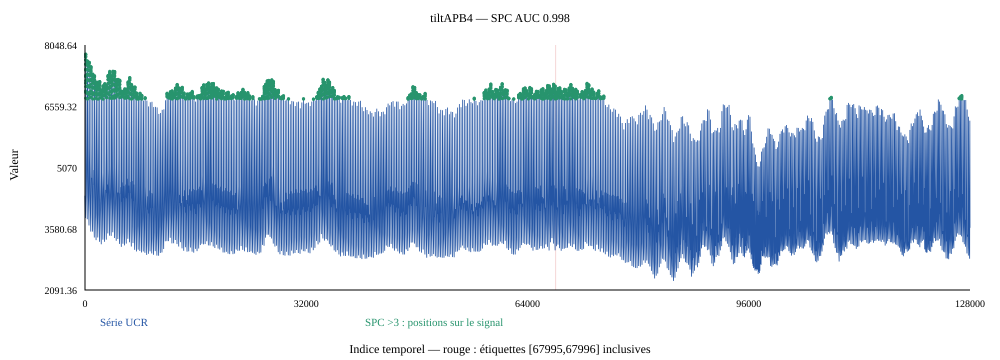

In [3]:
record Svg(string Content);
Formatter.Register<Svg>((s, w) => w.Write(s.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
// Le MIME image conserve les figures dans les lecteurs statiques de notebooks.
void AfficherSvg(Svg figure)
{
    display(figure, "image/svg+xml");
}

string F(double v) => v.ToString("0.###", CultureInfo.InvariantCulture);
string Esc(string s) => System.Security.SecurityElement.Escape(s);
// Rendering only: retain min and max in chronological order in each horizontal bin.
IEnumerable<int> IndicesDessin(double[] y, int bins = 1600)
{
    if (y.Length <= bins * 2)
        return Enumerable.Range(0, y.Length);
    var indices = new SortedSet<int>
    {
        0,
        y.Length - 1
    };
    for (int b = 0; b < bins; b++)
    {
        int lo = b * y.Length / bins, hi = (b + 1) * y.Length / bins;
        int mn = lo, mx = lo;
        for (int i = lo + 1; i < hi; i++)
        {
            if (y[i] < y[mn])
                mn = i;
            if (y[i] > y[mx])
                mx = i;
        }

        indices.Add(mn);
        indices.Add(mx);
    }

    return indices;
}

string Courbes(double[][] y, string[] legends, SerieUcr serie, string titre, string axe = "Valeur", int[] alertes = null)
{
    const int W = 1000, H = 360, L = 85, R = 30, T = 45, B = 70;
    double min = y.SelectMany(a => a).Min(), max = y.SelectMany(a => a).Max();
    double pad = Math.Max((max - min) * .04, 1e-10);
    min -= pad;
    max += pad;
    double X(int i) => L + i / (double)(serie.Valeurs.Length - 1) * (W - L - R);
    double Y(double v) => H - B - (v - min) / (max - min) * (H - T - B);
    var sb = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}'><rect width='100%' height='100%' fill='white'/><text x='500' y='22' text-anchor='middle'>{Esc(titre)}</text><rect x='{F(X(serie.Debut))}' y='{T}' width='{F(Math.Max(1, X(serie.Fin + 1) - X(serie.Debut)))}' height='{H - T - B}' fill='#c33' opacity='0.2'/>");
    string[] colors =
    {
        "#2455a4",
        "#d66b00",
        "#27946d"
    };
    for (int k = 0; k < y.Length; k++)
    {
        string points = string.Join(" ", IndicesDessin(y[k]).Select(i => $"{F(X(i))},{F(Y(y[k][i]))}"));
        sb.Append($"<polyline points='{points}' fill='none' stroke='{colors[k % 3]}' stroke-width='0.8'/><text x='{L + 15 + k * 265}' y='{H - 34}' fill='{colors[k % 3]}' font-size='11'>{Esc(legends[k])}</text>");
    }

    if (alertes != null)
    {
        foreach (int i in alertes)
            sb.Append($"<circle cx='{F(X(i))}' cy='{F(Y(serie.Valeurs[i]))}' r='1.6' fill='#27946d'/>");
        sb.Append($"<text x='{L + 280}' y='{H - 34}' fill='#27946d' font-size='11'>SPC &gt;3 : positions sur le signal</text>");
    }

    sb.Append($"<path d='M {L} {T} V {H - B} H {W - R}' fill='none' stroke='black'/>");
    for (int i = 0; i <= 4; i++)
    {
        double v = min + (max - min) * i / 4;
        int ix = (serie.Valeurs.Length - 1) * i / 4;
        sb.Append($"<text x='{L - 8}' y='{F(Y(v) + 4)}' text-anchor='end' font-size='10'>{F(v)}</text><text x='{F(X(ix))}' y='{H - B + 17}' text-anchor='middle' font-size='10'>{ix}</text>");
    }

    return sb.Append($"<text transform='translate(18,165) rotate(-90)' text-anchor='middle'>{Esc(axe)}</text><text x='500' y='{H - 7}' text-anchor='middle'>Indice temporel — rouge : étiquettes [{serie.Debut},{serie.Fin}] inclusives</text></svg>").ToString();
}

AfficherSvg(new Svg(Courbes(new[] { s1.Valeurs }, new[] { "Série UCR" }, s1, $"{s1.Nom} — SPC AUC {aucSpc1:F3}", alertes: Enumerable.Range(0, spc1.Length).Where(i => spc1[i] > 3).ToArray())));


## 2. MLP de prévision, pas auto-encodeur

Les 20 observations d'une fenêtre prédisent une seule cible scalaire. L'alignement source est conservé : X[i]=x[i:i+20], y[i]=x[i+21], donc deux pas après le dernier point observé. Les 21 premiers scores sont nuls par convention. L'erreur est |prévision−cible|.

C# construit toutes les fenêtres/cibles et les transfère sans arrondi en IEEE 754 vers le vrai backend. Scaler **et** réseau sont ajustés uniquement sur la première moitié des fenêtres : le scaler ne voit pas les fenêtres de test, corrigeant la fuite héritée des deux versions. MLP de 32 neurones, maximum 1200 itérations, graine 0, early_stopping, patience 30 et pas 1e-3 ; aucun budget réduit.

La moitié d'entraînement est supposée saine, hypothèse à examiner. Les AUC affichées utilisent la série complète, y compris train et préfixe nul : elles ne sont pas exclusivement holdout. Le score SPC reste global. Le temps d'apprentissage comparatif contrôlé n'est pas mesuré.

MLP : train 63990 fenêtres ×20, 117 itérations (max1200), AUC 0.901 ; SPC 0.998


Préfixe 21 scores nuls ; AUC sur série complète, pas seulement holdout.


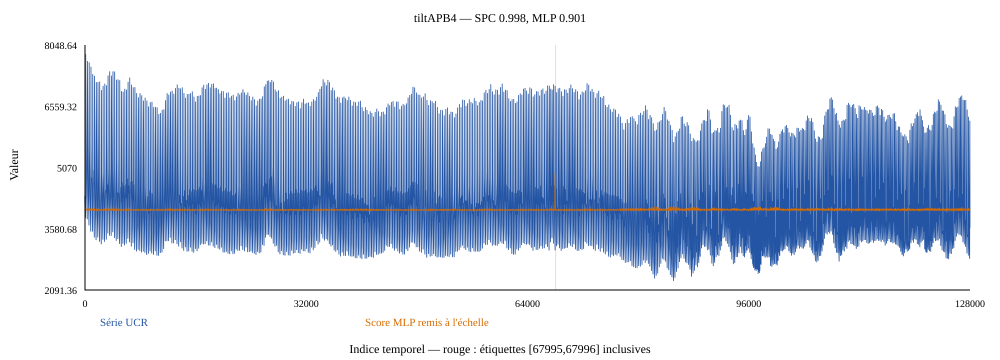

In [4]:
// La cible x[i+window+1] conserve un horizon de deux pas après la fenêtre.
// Le scaler et le MLP sont ajustés sur la première moitié uniquement ; les scores de préfixe restent nuls.
record ResultatMlp(double[] Scores, int TrainRows, int Iterations, double[] MoyennesScaler);
string Base64(double[] values)
{
    var bytes = new byte[values.Length * sizeof(double)];
    Buffer.BlockCopy(values, 0, bytes, 0, bytes.Length);
    return Convert.ToBase64String(bytes);
}

ResultatMlp PrevoirMlp(double[] x, int window = 20, int[] hidden = null, int seed = 0)
{
    if (x.Length < window + 5)
        return new ResultatMlp(new double[x.Length], 0, 0, Array.Empty<double>());
    int rows = x.Length - window - 1, cut = rows / 2;
    var features = new double[rows * window];
    var targets = new double[rows];
    for (int i = 0; i < rows; i++)
    {
        Array.Copy(x, i, features, i * window, window);
        targets[i] = x[i + window + 1];
    }

    string code = @"import base64,numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
X=np.frombuffer(base64.b64decode(cfg['features']),dtype=cfg['dtype']).reshape(cfg['rows'],cfg['window'])
y=np.frombuffer(base64.b64decode(cfg['targets']),dtype=cfg['dtype'])
cut=cfg['cut']
sc=StandardScaler().fit(X[:cut])
Xs=sc.transform(X)
reg=MLPRegressor(hidden_layer_sizes=tuple(cfg['hidden']),max_iter=1200,random_state=cfg['seed'],early_stopping=True,n_iter_no_change=30,learning_rate_init=1e-3)
reg.fit(Xs[:cut],y[:cut])
err=np.abs(reg.predict(Xs)-y)
result_json=json.dumps({'error':err.tolist(),'iterations':int(reg.n_iter_),'mean':sc.mean_.tolist()},allow_nan=False)";
    var payload = new
    {
        features = Base64(features),
        targets = Base64(targets),
        dtype = BitConverter.IsLittleEndian ? "<f8" : ">f8",
        rows,
        window,
        cut,
        hidden = hidden ?? new[]
        {
            32
        },
        seed
    };
    using var doc = JsonDocument.Parse(Backend(code, payload));
    var root = doc.RootElement;
    var err = JsonSerializer.Deserialize<double[]>(root.GetProperty("error").GetRawText());
    var scores = new double[x.Length];
    Array.Copy(err, 0, scores, window + 1, err.Length);
    return new ResultatMlp(scores, cut, root.GetProperty("iterations").GetInt32(), JsonSerializer.Deserialize<double[]>(root.GetProperty("mean").GetRawText()));
}

var mlp1 = PrevoirMlp(s1.Valeurs);
double aucMlp1 = Auc(s1.Labels, mlp1.Scores);
Console.WriteLine($"MLP : train {mlp1.TrainRows} fenêtres ×20, {mlp1.Iterations} itérations (max1200), AUC {aucMlp1:F3} ; SPC {aucSpc1:F3}");
Console.WriteLine("Préfixe 21 scores nuls ; AUC sur série complète, pas seulement holdout.");
double maxMlp = Math.Max(mlp1.Scores.Max(), 1e-12), stdAffiche = Std(s1.Valeurs), moyAffiche = Moy(s1.Valeurs);
var mlpAffiche = mlp1.Scores.Select(v => v / maxMlp * stdAffiche + moyAffiche).ToArray();
AfficherSvg(new Svg(Courbes(new[] { s1.Valeurs, mlpAffiche }, new[] { "Série UCR", "Score MLP remis à l'échelle" }, s1, $"{s1.Nom} — SPC {aucSpc1:F3}, MLP {aucMlp1:F3}")));


### Changer de série : InternalBleeding16

Réappliquons les mêmes modèles à la même série UCR que la source. SPC regarde les écarts à sa moyenne globale, le MLP exploite une fenêtre de prévision. Les AUC mesurent deux classements sur ces annotations ; elles ne prouvent pas l'impossibilité universelle de SPC face à un décalage ni la causalité exclusive du contexte dans leur différence.

InternalBleeding16 : 7501 valeurs, 13 positifs ; SPC 0.201, MLP 0.973, train 3740, itérations 540


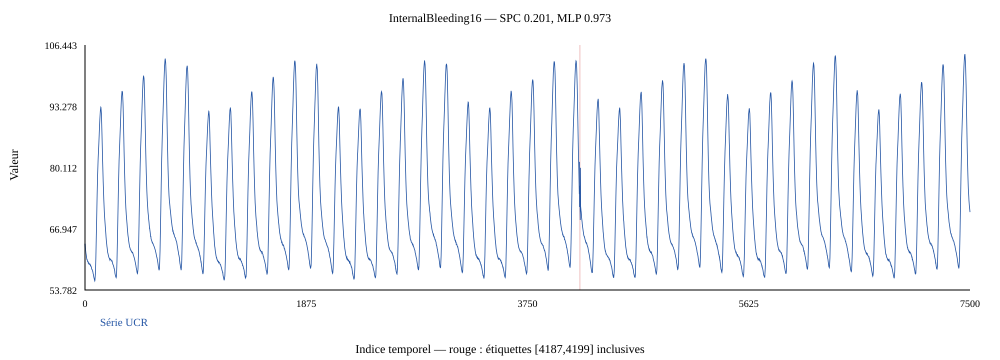

In [5]:
const string Contextuelle = "135_UCR_Anomaly_InternalBleeding16_1200_4187_4199.txt";
var s2 = Charger(Contextuelle);
var mlp2 = PrevoirMlp(s2.Valeurs);
double aucSpc2 = Auc(s2.Labels, Spc(s2.Valeurs)), aucMlp2 = Auc(s2.Labels, mlp2.Scores);
Console.WriteLine($"{s2.Nom} : {s2.Valeurs.Length} valeurs, {s2.Labels.Sum()} positifs ; SPC {aucSpc2:F3}, MLP {aucMlp2:F3}, train {mlp2.TrainRows}, itérations {mlp2.Iterations}");
AfficherSvg(new Svg(Courbes(new[] { s2.Valeurs }, new[] { "Série UCR" }, s2, $"{s2.Nom} — SPC {aucSpc2:F3}, MLP {aucMlp2:F3}")));


### Exercice 1 — Contraste SPC entre zone et fond

Implémentez le diagnostic renvoyant, dans l'ordre : AUC SPC, pic intérieur,99e centile extérieur, nombre total d'alertes>3, vrais positifs. Le garde teste InternalBleeding16et trois petites fixtures variées. Comparez ensuite SPC au MLP sur la série réelle et expliquez ce que l'AUC dit et ne dit pas du seuil ; ne postulez pas un échec avant le calcul.

In [6]:
bool VerifierDiagnostic(Func<double[], int[], double[]> fonction)
{
    if (fonction == null)
        return false;
    var essais = new[]
    {
        (X: Enumerable.Range(0, 20).Select(i => i == 19 ? 10.0 : 0.0).ToArray(), L: Enumerable.Range(0, 20).Select(i => i == 19 ? 1 : 0).ToArray()),
        (X: s2.Valeurs, L: s2.Labels),
        (X: new double[] { 0, 0, 0, 0, 4, 0, -4, 0, 0, 0 }, L: new[] { 0, 0, 0, 0, 1, 0, 1, 0, 0, 0 }),
        (X: Enumerable.Range(1, 8).Select(i => (double)i).ToArray(), L: new[] { 0, 0, 0, 0, 0, 0, 1, 1 })
    };
    foreach (var z in essais)
    {
        var s = Spc(z.X);
        var attendu = new[]
        {
            Auc(z.L, s),
            s.Where((v, i) => z.L[i] == 1).Max(),
            Quantile(s.Where((v, i) => z.L[i] == 0).ToArray(), .99),
            (double)s.Count(v => v > 3),
            (double)s.Where((v, i) => z.L[i] == 1).Count(v => v > 3)
        };
        var r = fonction((double[])z.X.Clone(), (int[])z.L.Clone());
        if (r == null || r.Length != 5 || r.Any(v => !double.IsFinite(v)) || r.Zip(attendu).Any(v => Math.Abs(v.First - v.Second) > 1e-10))
            return false;
    }

    return true;
}

Func<double[], int[], double[]> diagnosticSpc = null; // TODO : AUC, pic intérieur, p99 extérieur, alertes, vrais positifs
Console.WriteLine(diagnosticSpc == null ? "Exercice 1 à compléter" : $"Diagnostic valide : {VerifierDiagnostic(diagnosticSpc)}");


Exercice 1 à compléter


## 3. Quatre mécanismes à contrôler

### 1 — Force d'une baseline

Réafficher les deux AUC aide à justifier une complexité supplémentaire ; cela ne qualifie pas tout le benchmark.

### 2 — Densité des étiquettes

Mesurons les cinq séries complètes, avec leurs empreintes. Une densité plausible dépend du contexte et de la définition de l'événement : ni 1% ni 5% n'est un seuil universel établi ici. Une forte prévalence peut favoriser l'accuracy d'une règle majoritaire ; elle ne rend pas automatiquement l'AUC de classement facile.

In [7]:
// Les cinq fichiers restent distincts et leurs empreintes sont imprimées avec les densités.
// La médiane porte sur cet extrait, sans fixer un seuil universel de plausibilité des annotations.
Console.WriteLine($"Baseline simple sur {s1.Nom} : SPC AUC {aucSpc1:F3}, MLP {aucMlp1:F3} ; AUC distincte de la décision >3.");
string[] fichiers =
{
    Ponctuelle,
    "162_UCR_Anomaly_WalkingAceleration5_2700_5920_5979.txt",
    "248_UCR_Anomaly_weallwalk_2000_4702_4707.txt",
    Contextuelle,
    "110_UCR_Anomaly_2sddb40_35000_56600_56900.txt"
};
var series = fichiers.Select(Charger).ToArray();
var densites = new List<double>();
foreach (var serie in series)
{
    double d = 100.0 * serie.Labels.Sum() / serie.Labels.Length;
    densites.Add(d);
    Console.WriteLine($"{serie.Nom, -24} : {serie.Valeurs.Length} valeurs, {serie.Labels.Sum()} positifs, densité {d:F4}% ; SHA256 {serie.Sha256}");
}

Console.WriteLine($"Médiane des cinq densités : {Quantile(densites.ToArray(), .5):F4}% ; aucune borne universelle de plausibilité déduite.");


Baseline simple sur tiltAPB4 : SPC AUC 0.998, MLP 0.901 ; AUC distincte de la décision >3.


tiltAPB4                 : 128001 valeurs, 2 positifs, densité 0.0016% ; SHA256 420707d4f46dfb4483c0df43909afe76faac8a31cf4380202cd90f81d55fbac7


WalkingAceleration5      : 6684 valeurs, 60 positifs, densité 0.8977% ; SHA256 0b87854c390183094d8dd547e9517647bb285939066304ad3d133f8234cbe2cb


weallwalk                : 8432 valeurs, 6 positifs, densité 0.0712% ; SHA256 3b382c5a4e6208fb7932be05ad1f2e97498ed44b2f7ae7573fda20b18aba42bb


InternalBleeding16       : 7501 valeurs, 13 positifs, densité 0.1733% ; SHA256 a965019d130b1b8f2e49974f3ed7f20675bf7014b4952240ed4c8e338a2fa86f


2sddb40                  : 80001 valeurs, 301 positifs, densité 0.3762% ; SHA256 cf909cb2238c9851cc164a23bbbfd50b09226427c61a74d022c4e210064b8f29


Médiane des cinq densités : 0.1733% ; aucune borne universelle de plausibilité déduite.


### Exercice 2 — Densité et règles constantes

Renvoyez densité positive, accuracy « tout normal », accuracy « tout anormal » et AUC d'un score constant. Appliquez au cas UCR rare et à des étiquettes artificielles 50% positives, puis discutez la plausibilité pour un contexte précis. Les gardes font varier la prévalence et incluent la série réelle. Pourquoi la densité ne suffit-elle pas à augmenter l'AUC d'un score constant ?

In [8]:
bool VerifierDensite(Func<int[], double[]> fonction)
{
    if (fonction == null)
        return false;
    foreach (var labels in new[]
    {
        s1.Labels,
        new[]
        {
            0,
            0,
            0,
            1
        },
        new[]
        {
            0,
            0,
            1,
            1
        },
        new[]
        {
            0,
            1,
            1,
            1
        }
    }

    )
    {
        double d = labels.Average();
        var attendu = new[]
        {
            d,
            1 - d,
            d,
            .5
        };
        var r = fonction((int[])labels.Clone());
        if (r == null || r.Length != 4 || r.Any(v => !double.IsFinite(v)) || r.Zip(attendu).Any(v => Math.Abs(v.First - v.Second) > 1e-12))
            return false;
    }

    return true;
}

Func<int[], double[]> analyserDensite = null; // TODO : densité, accuracy tout normal/anormal, AUC constante
Console.WriteLine(analyserDensite == null ? "Exercice 2 à compléter" : $"Mesures valides : {VerifierDensite(analyserDensite)}");


Exercice 2 à compléter


### 3 — Sensibilité aux annotations

Les étiquettes de WalkingAceleration5sont décalées de 0,30 et 120 indices. Le signal et le score restent fixes. Les variations d'AUC illustrent leur dépendance aux annotations ; ce décalage artificiel n'est pas la preuve que les annotations de ce fichier sont fausses. Aucun jeu Yahoo externe n'est téléchargé ou évalué.

In [9]:
// Le signal et ses scores restent fixes pendant que la région positive est déplacée.
// Les extrémités sont tronquées aux bornes de la série ; ces labels artificiels testent la métrique, pas la vérité terrain.
int[] Decaler(int[] labels, int shift)
{
    var y = new int[labels.Length];
    var idx = Enumerable.Range(0, labels.Length).Where(i => labels[i] == 1).ToArray();
    if (idx.Length == 0)
        return y;
    int lo = Math.Max(0, idx.First() + shift), hi = Math.Min(labels.Length - 1, idx.Last() + shift);
    for (int i = lo; i <= hi; i++)
        y[i] = 1;
    return y;
}

var s3 = series[1];
var spc3 = Spc(s3.Valeurs);
foreach (int shift in new[]
{
    0,
    30,
    120
}

)
    Console.WriteLine($"{s3.Nom} : décalage {shift}, AUC SPC {Auc(Decaler(s3.Labels, shift), spc3):F3}");
Console.WriteLine("Même score, annotations artificiellement décalées : variations mesurées, pas preuve d'une erreur d'annotation réelle.");


WalkingAceleration5 : décalage 0, AUC SPC 0.962


WalkingAceleration5 : décalage 30, AUC SPC 0.778


WalkingAceleration5 : décalage 120, AUC SPC 0.417


Même score, annotations artificiellement décalées : variations mesurées, pas preuve d'une erreur d'annotation réelle.


### 4 — Position « run-to-failure »

Le score croît avec l'indice et n'examine pas le signal. Une région tardive obtient alors souvent un classement favorable. Les AUC de cette baseline et de SPC sont comparées sur WalkingAceleration5; une bonne AUC de position ne démontre pas une détection du contenu. Varier les positions et comparer à cette référence aide à qualifier un protocole.

WalkingAceleration5 : événement à 88.6% ; AUC position 0.894, SPC 0.962


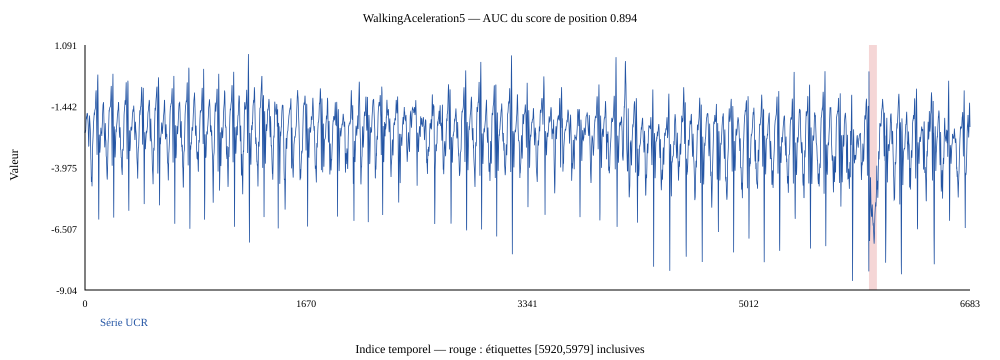

In [10]:
double[] ScorePosition(int n) => Enumerable.Range(0, n).Select(i => i / (double)(n - 1)).ToArray();
var rtf = ScorePosition(s3.Labels.Length);
double aucRtf = Auc(s3.Labels, rtf);
Console.WriteLine($"{s3.Nom} : événement à {100.0 * s3.Debut / s3.Labels.Length:F1}% ; AUC position {aucRtf:F3}, SPC {Auc(s3.Labels, spc3):F3}");
AfficherSvg(new Svg(Courbes(new[] { s3.Valeurs }, new[] { "Série UCR" }, s3, $"{s3.Nom} — AUC du score de position {aucRtf:F3}")));


### Exercice 3 — Mesurer le biais de position

L'exemple de baseline croissante est conservé ci-dessus. Ajoutez une fonction calculant son AUC pour une région positive inclusive [début,fin] dans une série de n points. Testez début, milieu et toute fin ; le garde varie longueur et largeur. Montrez sur une série factice qu'une région finale reçoit un classement élevé sans examen de ses valeurs, puis expliquez le caractère trompeur du score pour la détection du contenu.

In [11]:
bool VerifierPosition(Func<int, int, int, double?> fonction)
{
    if (fonction == null)
        return false;
    foreach (var z in new[]
    {
        (N: 100, S: 90, E: 99),
        (N: 100, S: 0, E: 9),
        (N: 60, S: 20, E: 25),
        (N: 80, S: 51, E: 73)
    }

    )
    {
        var labels = new int[z.N];
        for (int i = z.S; i <= z.E; i++)
            labels[i] = 1;
        double attendu = Auc(labels, ScorePosition(z.N));
        var r = fonction(z.N, z.S, z.E);
        if (!r.HasValue || !double.IsFinite(r.Value) || Math.Abs(r.Value - attendu) > 1e-12)
            return false;
    }

    return true;
}

Func<int, int, int, double?> effetPosition = null; // TODO : AUC pour [début,fin] dans une série de n points
Console.WriteLine(effetPosition == null ? "Exercice 3 à compléter" : $"Positions valides : {VerifierPosition(effetPosition)}");


Exercice 3 à compléter


## 4. Changer de série : 2sddb40La troisième expérience entraînée garde les mêmes modèles et paramètres sur 80001 points réels. Une AUC<0.5 signifie un classement inversé sous la convention « grand score = anomalie » ; une AUC proche 0.5 ne prouve pas l'absence de toute information.

Les différences entre les trois séries ne certifient ni qualité générale du benchmark, ni supériorité d'une famille, ni nécessité d'une méthode unique. Il manque une étude multi-graines/hyperparamètres et une évaluation de généralisation pour de telles conclusions.

2sddb40 : densité 0.376% ; SPC AUC 0.172, MLP 0.355, train 39990, itérations 424


AUC<0.5 : classement inversé dans cette convention ; aucune certification de qualité du benchmark.


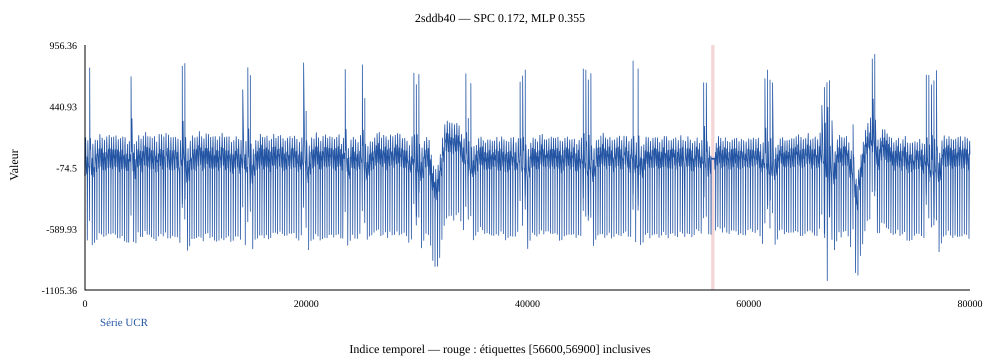

In [12]:
var s6 = series[4];
var spc6 = Spc(s6.Valeurs);
var mlp6 = PrevoirMlp(s6.Valeurs);
double aucSpc6 = Auc(s6.Labels, spc6), aucMlp6 = Auc(s6.Labels, mlp6.Scores);
Console.WriteLine($"{s6.Nom} : densité {100.0 * s6.Labels.Sum() / s6.Labels.Length:F3}% ; SPC AUC {aucSpc6:F3}, MLP {aucMlp6:F3}, train {mlp6.TrainRows}, itérations {mlp6.Iterations}");
Console.WriteLine("AUC<0.5 : classement inversé dans cette convention ; aucune certification de qualité du benchmark.");
AfficherSvg(new Svg(Courbes(new[] { s6.Valeurs }, new[] { "Série UCR" }, s6, $"{s6.Nom} — SPC {aucSpc6:F3}, MLP {aucMlp6:F3}")));


## Résumé

Les cinq séries réelles sont conservées, trois MLP sont ajustés avec les mêmes fenêtres/budgets et cinq figures sont affichées. Les quatre mécanismes — baseline, densité, annotations, position — influencent des aspects différents de l'évaluation. Les trois exercices ouverts demandent calcul et interprétation.

## À retenir
AUC, seuil et accuracy sont distincts ; scaler/réseau sont ajustés sur train, mais SPC global reste descriptif. Les résultats d'une série ou d'une graine ne qualifient pas toute une littérature.

## Vérifiez votre compréhension
Un score constant obtient-il une AUC élevée quand 80% des points sont positifs ?
<details><summary>Réponse</summary>Avec les deux classes, tous les rangs sont ex æquo et l'AUC vaut 0.5 ; une règle majoritaire peut pourtant avoir une accuracy de 80%.</details>

## Pour aller plus loin
Poursuivez avec [ML-09c C# — Matrix Profile](ML-09c-MatrixProfile-Multidim-CSharp.ipynb) et consultez le [Python primaire](ML-09b-TSAD-Benchmark-Flaws-Python.ipynb) pour son contexte historique.